In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from pathlib import Path

import re
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Loc 00

In [2]:
RANDOM_STATE = 42
df = pd.read_parquet("year_TERZ_00_results_cut/qtransform_features.parquet")

feature_columns = [col for col in df.columns if col.startswith("feature_")]
if len(feature_columns) == 0:
    raise ValueError("No feature_* columns found.")

print(f"Number of features: {len(feature_columns)}")

X = df[feature_columns].to_numpy(dtype="float64")
print(f"X.shape = {X.shape}")

X_max = X.max(axis=1, keepdims=True)
#X_max = X_max.T
#print(X_max[0])

Number of features: 1230
X.shape = (94463, 1230)


In [3]:
X_norm = X / X_max

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_norm)
print(f"Scaled matrix: {X_scaled.shape}") 

Scaled matrix: (94463, 1230)


In [ ]:
PCA_COMPONENTS = 300

n_components = min(PCA_COMPONENTS,X_scaled.shape[0] - 1,X_scaled.shape[1])
pca = PCA(n_components=n_components,random_state=RANDOM_STATE)

X_pca = pca.fit_transform(X_scaled)
explained_variance = np.sum(pca.explained_variance_ratio_)

print(f"PCA components: {n_components}")
print(f"Explained variance: {explained_variance:.4f}")

PCA components: 300
Explained variance: 0.9313


In [14]:
tsne = TSNE(n_components=2,perplexity=300,early_exaggeration=100,init="pca",learning_rate="auto",random_state=RANDOM_STATE, metric='euclidean', verbose=1, n_jobs=-1)
X_tsne = tsne.fit_transform(X_pca)

[t-SNE] Computing 901 nearest neighbors...
[t-SNE] Indexed 94463 samples in 0.109s...
[t-SNE] Computed neighbors for 94463 samples in 110.943s...
[t-SNE] Computed conditional probabilities for sample 1000 / 94463
[t-SNE] Computed conditional probabilities for sample 2000 / 94463
[t-SNE] Computed conditional probabilities for sample 3000 / 94463
[t-SNE] Computed conditional probabilities for sample 4000 / 94463
[t-SNE] Computed conditional probabilities for sample 5000 / 94463
[t-SNE] Computed conditional probabilities for sample 6000 / 94463
[t-SNE] Computed conditional probabilities for sample 7000 / 94463
[t-SNE] Computed conditional probabilities for sample 8000 / 94463
[t-SNE] Computed conditional probabilities for sample 9000 / 94463
[t-SNE] Computed conditional probabilities for sample 10000 / 94463
[t-SNE] Computed conditional probabilities for sample 11000 / 94463
[t-SNE] Computed conditional probabilities for sample 12000 / 94463
[t-SNE] Computed conditional probabilities for 

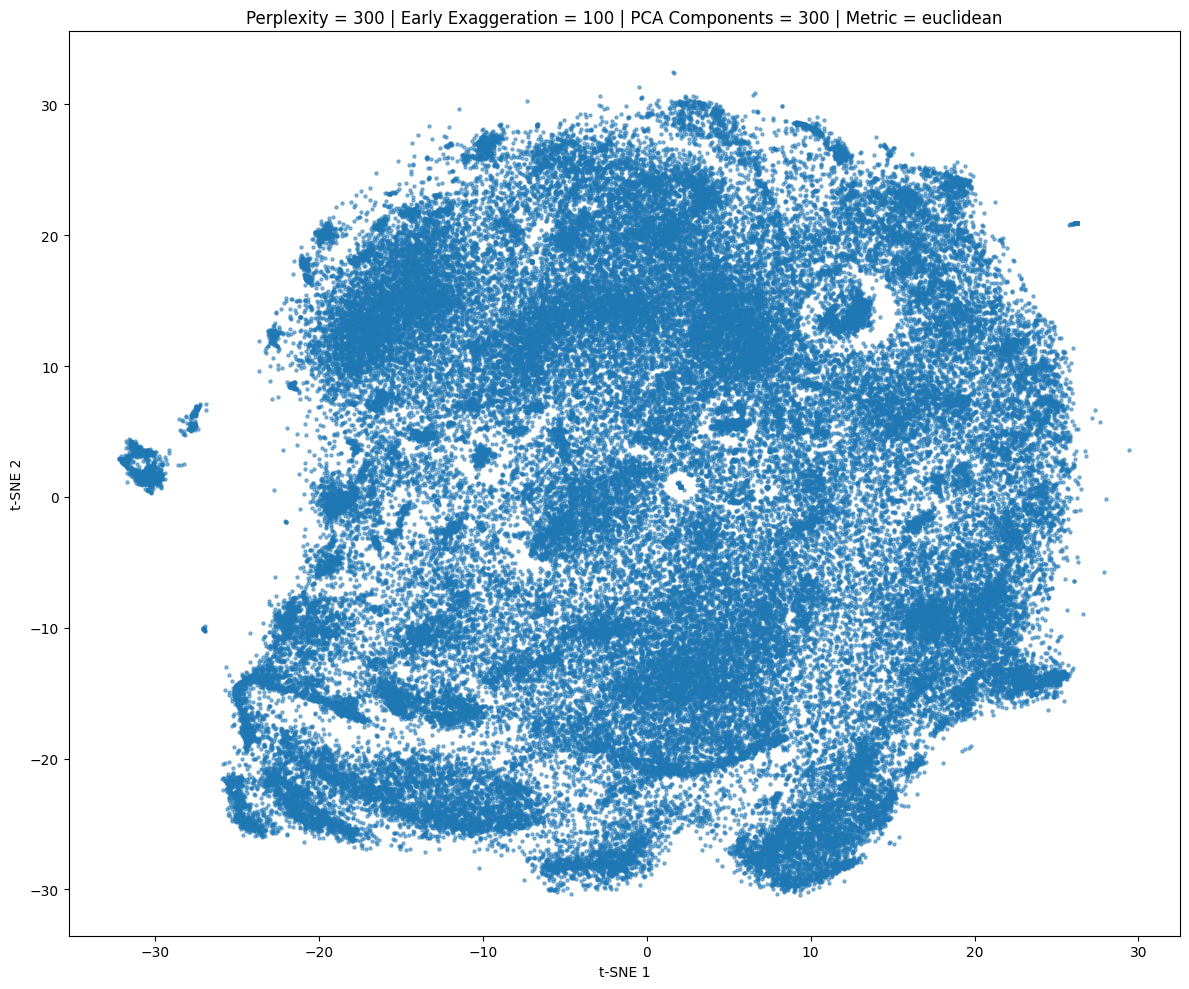

In [16]:
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],s=5,alpha=0.5)
ax.set_title(f"Perplexity = 300 | Early Exaggeration = 100 | PCA Components = {PCA_COMPONENTS} | Metric = euclidean")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

Loc 01

In [ ]:
RANDOM_STATE = 42
df = pd.read_parquet("year_TERZ_01_results_cut/qtransform_features.parquet")

feature_columns = [col for col in df.columns if col.startswith("feature_")]
if len(feature_columns) == 0:
    raise ValueError("No feature_* columns found.")

print(f"Number of features: {len(feature_columns)}")

X = df[feature_columns].to_numpy(dtype="float64")
print(f"X.shape = {X.shape}")

X_max = X.max(axis=1, keepdims=True)
#X_max = X_max.T
#print(X_max[0])

Number of features: 1230
X.shape = (2077, 1230)


In [ ]:
X_norm = X / X_max

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_norm)
print(f"Scaled matrix: {X_scaled.shape}") 


Scaled matrix: (2077, 1230)


In [ ]:
PCA_COMPONENTS = 40

n_components = min(PCA_COMPONENTS,X_scaled.shape[0] - 1,X_scaled.shape[1])
pca = PCA(n_components=n_components,random_state=RANDOM_STATE)

X_pca = pca.fit_transform(X_scaled)
explained_variance = np.sum(pca.explained_variance_ratio_)

print(f"PCA components: {n_components}")
print(f"Explained variance: {explained_variance:.4f}")

tsne = TSNE(n_components=2,perplexity=90,early_exaggeration=14,init="pca",learning_rate="auto",random_state=RANDOM_STATE, metric='cosine')
X_tsne = tsne.fit_transform(X_pca)

#20.8s

PCA components: 40
Explained variance: 0.6623


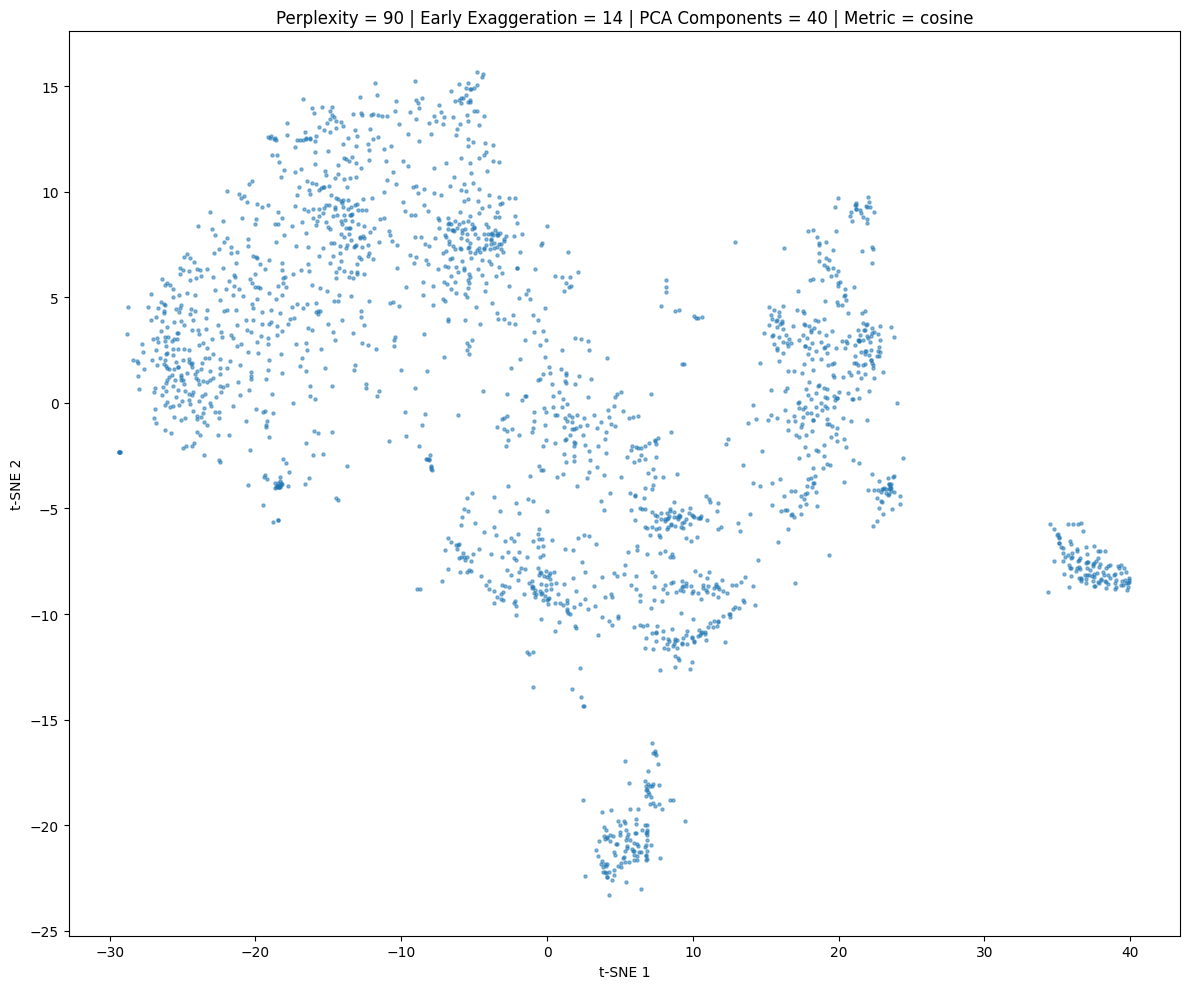

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],s=5,alpha=0.5)
ax.set_title(f"Perplexity = 90 | Early Exaggeration = 14 | PCA Components = {PCA_COMPONENTS} | Metric = cosine")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()